# **Baseline Machine Learning Model Development**

### Objective

This notebook focuses on developing an initial benchmark model for the Tanzania Tourism Classification task using **XGBoost (Extreme Gradient Boosting)** as the baseline classifier.

### Model Selection – Why XGBoost?

XGBoost was selected for the following reasons:

- **Strong Performance:** It is highly effective for structured and tabular datasets.
- **Non-linear Relationships:** It can capture complex patterns and relationships between features.
- **Feature Interactions:** It can identify interactions between different features during training.
- **Feature Importance:** It provides useful insights into the contribution of features to model predictions.
- **Missing Values:** It has built-in support for handling missing values.

### Modeling Approach

The process includes separating features from the target variable, encoding categorical features, and creating stratified training and validation sets.

The baseline model will be trained using initial hyperparameters and evaluated with appropriate classification metrics. Stratified K-Fold Cross-Validation will also be used to assess model stability and generalization performance.

The results will provide a reliable benchmark for future feature engineering, model experimentation, and hyperparameter optimization.

## **1. Import Required Libraries**

In [36]:
from pathlib import Path
import sys 

notebook_dir = Path.cwd()
project_root = notebook_dir.parent 

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import TRAIN_DATA_PATH, TEST_DATA_PATH, BASE_NUMERIC_COLS, BASE_CATEGORICAL_COLS, RANDOM_SEED, BASE_MODEL_PARAMS, N_SPLITS, MODELS_DIR, TEST_SIZE, TRAIN_DATA_FE_PATH, 
from src.preprocessing import Data_Preprocessor

import numpy as np
import pandas as pd

import xgboost as xgb
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold

import matplotlib.pyplot as plt
import seaborn as sns

SyntaxError: trailing comma not allowed without surrounding parentheses (762353181.py, line 10)

### Project Configuration and Imports

The notebook imports project settings from `src.config` so that paths, feature groups, model parameters, and random seeds are managed in one place.

This keeps the experiment consistent with the rest of the project and avoids hard-coding configuration values in multiple notebooks.

In [ ]:
pd.read_parquet(TRAIN_DATA_FE_PATH)

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,night_mainland,night_zanzibar,first_trip_tz,cost_category,total nights,total_adults,night_ratio,adults_per_night,male_to_female_ratio,continent
0,tour_id1hffseyw,ITALY,45-64,With Children,0.0,2.0,Visiting Friends and Relatives,Beach Tourism,"Friends, relatives",Package Tour,...,0,7,Yes,High Cost,7,2.0,0.00,0.29,0.00,EUROPE
1,tour_idnacd7zag,UNITED KINGDOM,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Wildlife Tourism,"Travel agent, tour operator",Package Tour,...,0,7,Yes,High Cost,7,2.0,0.00,0.29,1.00,EUROPE
2,tour_id62vz7e71,UNITED STATES OF AMERICA,65+,With Spouse,1.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,6,6,Yes,Higher Cost,12,2.0,1.00,0.17,1.00,NORTH AMERICA
3,tour_idrc76tzix,RWANDA,25-44,With Spouse and Children,3.0,1.0,Leisure and Holidays,Beach Tourism,"Radio, TV, Web",Independent,...,3,0,No,Lower Cost,3,4.0,0.00,1.33,0.33,AFRICA
4,tour_idn723m0n9,UNITED STATES OF AMERICA,45-64,Alone,0.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,7,0,Yes,Higher Cost,7,1.0,0.00,0.14,0.00,NORTH AMERICA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18501,tour_idmp5ciw50,KENYA,45-64,Alone,0.0,1.0,Other,Hunting Tourism,Others,Independent,...,3,0,No,Lower Cost,3,1.0,0.00,0.33,0.00,AFRICA
18502,tour_ideq0yncfs,KENYA,45-64,Alone,1.0,0.0,Meetings and Conference,Wildlife Tourism,Others,Independent,...,2,0,No,Lower Cost,2,1.0,0.00,0.50,0.00,AFRICA
18503,tour_idv7pz3vs8,UNITED STATES OF AMERICA,25-44,With Spouse and Children,2.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Independent,...,9,0,Yes,Higher Cost,9,3.0,0.00,0.33,0.50,NORTH AMERICA
18504,tour_idy6ydo00w,UNITED STATES OF AMERICA,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Conference Tourism,"Radio, TV, Web",Package Tour,...,13,4,No,Higher Cost,17,2.0,3.25,0.12,1.00,NORTH AMERICA


### Initial Dataset Inspection

The displayed Parquet file is an existing feature-engineered training dataset used here for inspection.

**Important:** The baseline pipeline below currently loads `TRAIN_DATA_PATH` and `TEST_DATA_PATH` through `Data_Preprocessor`. Therefore, this displayed Parquet file is not the input to the baseline model unless those configured paths are changed.

## **2. Data Preprocessing**

In [ ]:
train_df_processed = Data_Preprocessor(expected_columns=21, is_train=True)
train_processed = train_df_processed.process_pipeline(str(TRAIN_DATA_PATH))
#train_df_processed = Data_Preprocessor(expected_columns=27, is_train=True)
#train_processed = train_df_processed.process_pipeline(str(TRAIN_DATA_FE_PATH))

test_df_processed = Data_Preprocessor(expected_columns=20, is_train=False)
test_processed = test_df_processed.process_pipeline(str(TEST_DATA_PATH))
#test_df_processed = Data_Preprocessor(expected_columns=26, is_train=False)  
#test_processed = test_df_processed.process_pipeline(str(TEST_DATA_FE_PATH))

print(f"train shape {train_processed.shape}")
print(f"test shape {test_processed.shape}")

train shape (18478, 21)
test shape (6169, 20)


### Preprocessing Output

The preprocessing pipeline returned:

- Training data: **18,478 rows and 21 columns**.
- Test data: **6,169 rows and 20 columns**.

The training dataset contains the target column, while the competition test dataset does not. Confirm that any rows removed during preprocessing were handled intentionally and that the same feature transformations are applied consistently to both datasets.

In [ ]:
train_processed.columns

Index(['Tour_ID', 'country', 'age_group', 'travel_with', 'total_female',
       'total_male', 'purpose', 'main_activity', 'info_source',
       'tour_arrangement', 'package_transport_int', 'package_accomodation',
       'package_food', 'package_transport_tz', 'package_sightseeing',
       'package_guided_tour', 'package_insurance', 'night_mainland',
       'night_zanzibar', 'first_trip_tz', 'cost_category'],
      dtype='object')

### Schema Check

The training dataset contains:

- `Tour_ID`: the record identifier.
- 19 predictor columns.
- `cost_category`: the target variable.

Checking the schema before modeling helps confirm that the expected columns are available and that the identifier and target can be excluded from the feature matrix.

## **3. Target & Feature Separation**

In [ ]:
target = train_processed['cost_category']
feature = train_processed.drop(columns=['Tour_ID','cost_category'])

### Feature and Target Separation

`cost_category` is separated as the target variable, while `Tour_ID` is removed from the predictors.

The identifier is excluded because it is a record key rather than a meaningful descriptive feature. This leaves the model with the available trip and traveler information to learn from.

## **4. Feature Type Identification**

In [ ]:
BASE_NUMERIC_COLS

['total_female', 'total_male', 'night_mainland', 'night_zanzibar']

In [ ]:
BASE_CATEGORICAL_COLS

['country',
 'age_group',
 'travel_with',
 'first_trip_tz',
 'purpose',
 'main_activity',
 'info_source',
 'tour_arrangement',
 'package_transport_int',
 'package_accomodation',
 'package_food',
 'package_transport_tz',
 'package_sightseeing',
 'package_guided_tour',
 'package_insurance']

### Feature Type Summary

The baseline configuration defines **4 numerical features** and **15 categorical features**.

Keeping these feature groups in `src.config` makes the preprocessing and modeling steps easier to maintain. It also provides a clear starting point for later feature engineering.

## **5. Baseline Modeling Strategy**

The first experiment uses an XGBoost multi-class classifier with six target classes.

The workflow is designed to:

- Establish a benchmark before feature engineering and hyperparameter tuning.
- Use class-balanced sample weights to reduce the effect of class imbalance.
- Monitor multi-class log loss during training.
- Evaluate the model with accuracy, class-level precision and recall, F1-scores, and cross-validation.

The initial model settings are loaded from `src.config` to keep the experiment reproducible and consistent with the project structure.

## **6. Train-Validation Split**

In [ ]:
X, y = feature, target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y)


### Stratified Holdout Split

The dataset is divided into training and holdout validation subsets using `train_test_split`.

The `stratify=y` argument helps preserve the target-class proportions in both subsets. The random seed makes the split reproducible, while `TEST_SIZE` is controlled through the project configuration.

In this notebook, `X_test` and `y_test` refer to the holdout validation subset created from the training data. They are not the separate competition `Test.csv` dataset.

## **7. Categorical Feature Encoding**

In [ ]:
encoder = OrdinalEncoder(
handle_unknown='use_encoded_value',
unknown_value=-1
)
X_train[BASE_CATEGORICAL_COLS] = encoder.fit_transform(X_train[BASE_CATEGORICAL_COLS])
X_test[BASE_CATEGORICAL_COLS] = encoder.transform(X_test[BASE_CATEGORICAL_COLS])

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

### Feature Type Summary

The baseline configuration defines **4 numerical features** and **15 categorical features**.

Keeping these feature groups in `src.config` makes the preprocessing and modeling steps easier to maintain. It also provides a clear starting point for later feature engineering.

In [ ]:
display(X_train.shape)
display(X_test.shape)

(14782, 19)

(3696, 19)

In [ ]:
display(y_train.shape)
display(y_test.shape)

(14782,)

(3696,)

### Shape Validation

The training and holdout feature matrices contain **19 columns**, and their target arrays have matching row counts.

These checks confirm that the split and encoding steps produced aligned feature and target data before model training.

## **8. Baseline Model Initialization**

In [ ]:
BASE_MODEL_PARAMS

{'max_depth': 5,
 'nthread': 4,
 'eval_metric': 'mlogloss',
 'objective': 'multi:softprob',
 'num_class': 6,
 'random_state': 42,
 'max_leaves': 15,
 'learning_rate': 0.01}

### Initial Hyperparameter Settings

The displayed configuration starts with these values:

- `objective='multi:softprob'`: predict class probabilities for the six classes.
- `num_class=6`: define the number of target categories.
- `max_depth=5` and `max_leaves=15`: limit tree complexity.
- `learning_rate=0.01`: use small boosting steps.
- `eval_metric='mlogloss'`: monitor probability quality across all classes.
- `nthread=4`: use four CPU threads.

These are initial baseline settings. Their values should be evaluated through later experiments rather than treated as optimized parameters.

### Baseline Modeling Design

This experiment uses XGBoost for a six-class classification problem.

The baseline objective is `multi:softprob`, which returns a probability for each target class. The `mlogloss` metric is used to monitor probabilistic predictions during training.

At this stage, the goal is to establish a reproducible benchmark with initial parameters, not to find the best possible configuration. Hyperparameter tuning and feature improvements will be handled in later experiments.

In [ ]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

dtrain = xgb.DMatrix(X_train, label=y_train, weight=sample_weights)
dtest = xgb.DMatrix(X_test, label=y_test)
param = BASE_MODEL_PARAMS
evallist = [(dtrain, 'train'), (dtest, 'test')]
evals_result = {}

num_round = 200

### Baseline Modeling Design

This experiment uses XGBoost for a six-class classification problem.

The baseline objective is `multi:softprob`, which returns a probability for each target class. The `mlogloss` metric is used to monitor probabilistic predictions during training.

At this stage, the goal is to establish a reproducible benchmark with initial parameters, not to find the best possible configuration. Hyperparameter tuning and feature improvements will be handled in later experiments.

## **9. Baseline Model Training**

In [ ]:
bst = xgb.train(param, dtrain, num_round, evallist,evals_result=evals_result,verbose_eval=True)

[0]	train-mlogloss:1.78515	test-mlogloss:1.78653
[1]	train-mlogloss:1.77865	test-mlogloss:1.78138


[2]	train-mlogloss:1.77258	test-mlogloss:1.77643
[3]	train-mlogloss:1.76660	test-mlogloss:1.77154
[4]	train-mlogloss:1.76040	test-mlogloss:1.76662
[5]	train-mlogloss:1.75461	test-mlogloss:1.76188
[6]	train-mlogloss:1.74890	test-mlogloss:1.75721
[7]	train-mlogloss:1.74329	test-mlogloss:1.75261
[8]	train-mlogloss:1.73775	test-mlogloss:1.74807
[9]	train-mlogloss:1.73230	test-mlogloss:1.74360
[10]	train-mlogloss:1.72693	test-mlogloss:1.73919
[11]	train-mlogloss:1.72170	test-mlogloss:1.73494
[12]	train-mlogloss:1.71632	test-mlogloss:1.73063
[13]	train-mlogloss:1.71126	test-mlogloss:1.72652
[14]	train-mlogloss:1.70628	test-mlogloss:1.72244
[15]	train-mlogloss:1.70136	test-mlogloss:1.71838
[16]	train-mlogloss:1.69652	test-mlogloss:1.71441
[17]	train-mlogloss:1.69174	test-mlogloss:1.71047
[18]	train-mlogloss:1.68703	test-mlogloss:1.70659
[19]	train-mlogloss:1.68237	test-mlogloss:1.70276
[20]	train-mlogloss:1.67778	test-mlogloss:1.69899
[21]	train-mlogloss:1.67324	test-mlogloss:1.69525
[22]	tra

/home/karim/anaconda3/lib/python3.13/site-packages/xgboost/core.py:771: FutureWarning: Pass `evals` as keyword args.
  warnings.warn(msg, FutureWarning)


[24]	train-mlogloss:1.65969	test-mlogloss:1.68414
[25]	train-mlogloss:1.65537	test-mlogloss:1.68058
[26]	train-mlogloss:1.65110	test-mlogloss:1.67704
[27]	train-mlogloss:1.64688	test-mlogloss:1.67355
[28]	train-mlogloss:1.64274	test-mlogloss:1.67008
[29]	train-mlogloss:1.63864	test-mlogloss:1.66664
[30]	train-mlogloss:1.63458	test-mlogloss:1.66328
[31]	train-mlogloss:1.63059	test-mlogloss:1.65996
[32]	train-mlogloss:1.62665	test-mlogloss:1.65670
[33]	train-mlogloss:1.62273	test-mlogloss:1.65344
[34]	train-mlogloss:1.61890	test-mlogloss:1.65028
[35]	train-mlogloss:1.61508	test-mlogloss:1.64709
[36]	train-mlogloss:1.61131	test-mlogloss:1.64395
[37]	train-mlogloss:1.60755	test-mlogloss:1.64076
[38]	train-mlogloss:1.60385	test-mlogloss:1.63766
[39]	train-mlogloss:1.60020	test-mlogloss:1.63458
[40]	train-mlogloss:1.59661	test-mlogloss:1.63159
[41]	train-mlogloss:1.59304	test-mlogloss:1.62861
[42]	train-mlogloss:1.58951	test-mlogloss:1.62565
[43]	train-mlogloss:1.58601	test-mlogloss:1.62272


### Training Progress

The training output reports multi-class log loss for the training and holdout validation subsets at each boosting round.

Compare both curves to understand whether the model is learning and whether the validation loss begins to diverge from the training loss. The holdout set is being used for monitoring in this baseline experiment; it should not be repeatedly used to select final modeling decisions.

## **10. Validation Prediction**

In [ ]:
ypred_prob = bst.predict(dtest)
ypred_classes = np.argmax(ypred_prob, axis=1)


### Converting Probabilities to Class Predictions

The model returns a probability distribution across the six classes for each observation.

`argmax` selects the class with the highest predicted probability. These class predictions are used for metrics such as accuracy, precision, recall, F1-score, and the confusion matrix.

## **11. Evaluation Metrics**

In [ ]:
accuracy = accuracy_score(y_test, ypred_classes)
print(f"Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, ypred_classes))

Accuracy: 0.4432

Classification Report:
              precision    recall  f1-score   support

           0       0.46      0.41      0.44       734
           1       0.67      0.50      0.57       972
           2       0.11      0.69      0.19        71
           3       0.19      0.34      0.25       313
           4       0.49      0.53      0.51       513
           5       0.54      0.39      0.45      1093

    accuracy                           0.44      3696
   macro avg       0.41      0.48      0.40      3696
weighted avg       0.51      0.44      0.47      3696



### Holdout Evaluation

The holdout results provide the first benchmark for this model:

- **Accuracy:** 44.32%.
- **Macro F1-score:** 0.40.
- **Weighted F1-score:** 0.47.

The difference between macro and weighted F1 indicates that performance varies across classes and that the larger classes have a stronger influence on the weighted score. The class-level report should be reviewed alongside accuracy, especially because this is a multi-class problem with an uneven target distribution.

These results are a starting point for comparison, not evidence that the model is ready for deployment.

Text(0.5, 1.0, 'Training and Validation Log Loss')

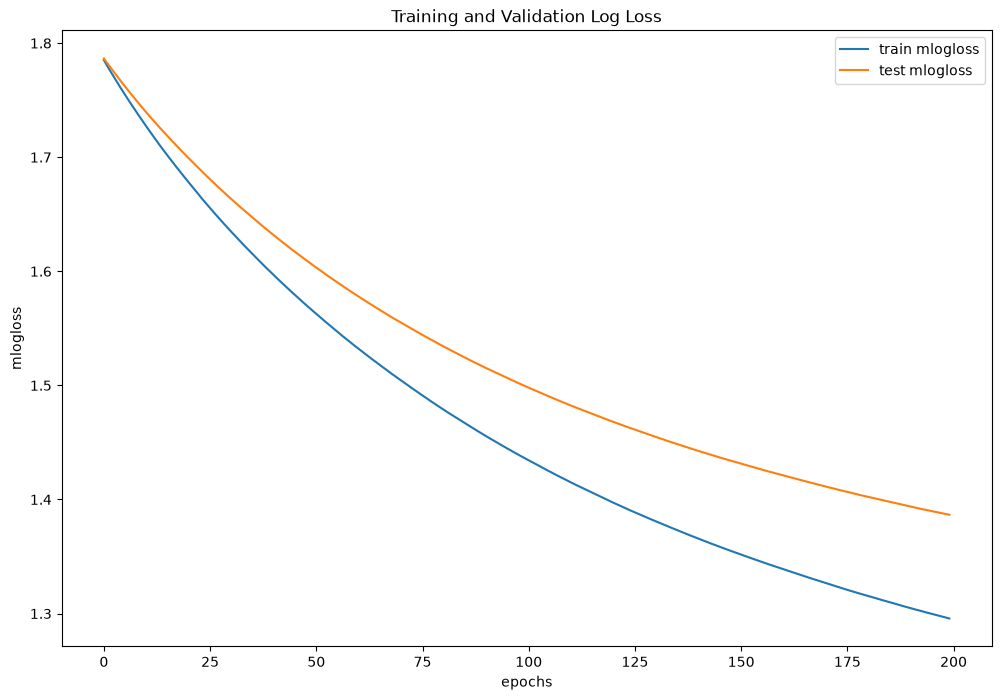

In [ ]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(evals_result['train']['mlogloss'],label='train mlogloss')
ax.plot(evals_result['test']['mlogloss'], label='test mlogloss')
ax.plot()
ax.legend()
plt.xlabel("epochs")
plt.ylabel('mlogloss')
plt.title("Training and Validation Log Loss")


### Learning Curve Interpretation

The plot compares training and validation log loss across boosting rounds.

A decreasing validation loss suggests improving probability estimates on the holdout data. A widening gap between training and validation loss can indicate overfitting. Use this plot together with the classification metrics rather than relying on accuracy alone.

## **12. Classification Performance Analysis**

In [ ]:
cm = confusion_matrix(y_test, ypred_classes)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[304 159  91  25   9 146]
 [165 484 229  13   5  76]
 [  2  16  49   0   0   4]
 [ 16   3   6 106 116  66]
 [ 24  14  10 129 271  65]
 [149  49  50 274 147 424]]


### Confusion Matrix Structure

The confusion matrix compares true class IDs (rows) with predicted class IDs (columns). Diagonal values represent correct predictions, while off-diagonal values show where the model confuses one class with another.

Before interpreting this matrix by class name, verify that the displayed label order exactly matches the integer mapping used by `LabelEncoder`.

In [ ]:
label_encoder.classes_ = ['Highest Cost', 'Higher Cost', 'High Cost','Normal Cost', 'Low Cost','Lower Cost']

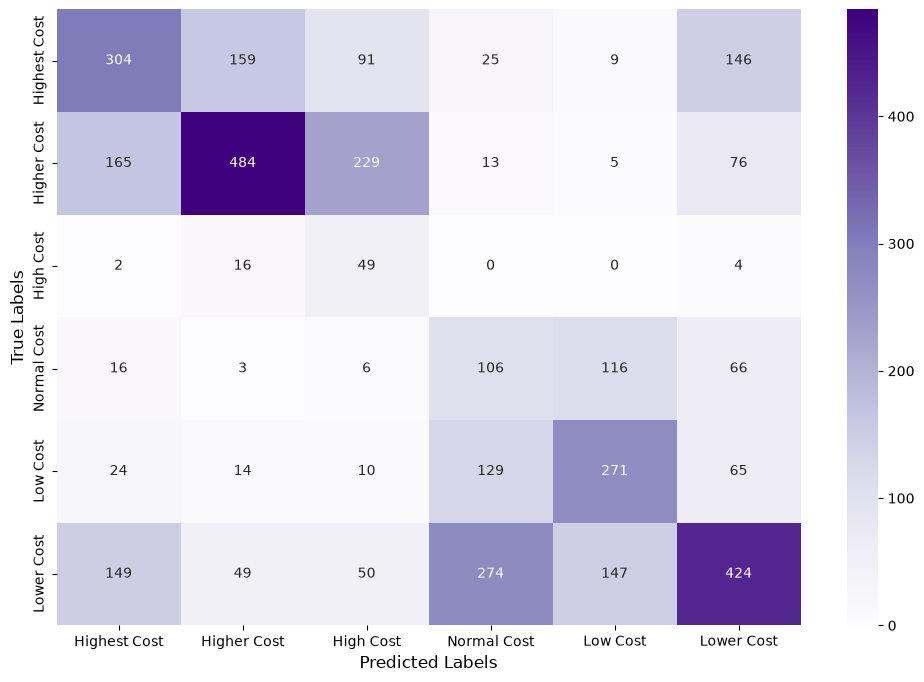

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(cm,annot=True,fmt='.0f',xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_,cmap='Purples')
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.show()

### Important Class-Label Mapping Check

`LabelEncoder` assigns class IDs in its original sorted `classes_` order. For the six labels in this notebook, that order is:

`High Cost`, `Higher Cost`, `Highest Cost`, `Low Cost`, `Lower Cost`, `Normal Cost`.

The next code cell manually replaces `label_encoder.classes_` with a different order after the target values have already been encoded. Changing `classes_` at this stage does **not** change the encoded target values; it only changes the names displayed on the heatmap.

Therefore, the current confusion-matrix class names do not match the class IDs and can lead to incorrect interpretation. Preserve the original `label_encoder.classes_` order and use it directly for the plot, or explicitly remap the target values before training.

## **13. Cross-Validation Strategy**

In [ ]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

### Cross-Validation Design

Stratified K-Fold divides the training subset into multiple folds while preserving class proportions as closely as possible.

Each fold is used once for validation, while the remaining folds are used for training. This provides a broader view of model stability than relying on one holdout split alone.

## **14. Cross-Validation Results**

In [ ]:
cv_scores = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_va = y_train[train_idx], y_train[val_idx]
    sample_weights = compute_sample_weight(class_weight='balanced',y=y_tr)

    d_tr = xgb.DMatrix(X_tr, label=y_tr, weight=sample_weights)
    d_va = xgb.DMatrix(X_va, label=y_va)
    
    evals = [(d_tr, 'train'), (d_va, 'val')]
    model = xgb.train(param, d_tr, num_round, evals=evals, verbose_eval=False)
    
    preds = model.predict(d_va)
    pred_classes = np.argmax(preds, axis=1)
    acc = np.mean(pred_classes == y_va)
    cv_scores.append(acc)
    ypred_prob = model.predict(d_va)

    ypred_prob_cl = np.argmax(ypred_prob, axis=1)
    
accuracy = accuracy_score(y_va, ypred_prob_cl)
print(classification_report(y_va, ypred_prob_cl))
print(f"Cross-Validation Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")

              precision    recall  f1-score   support

           0       0.46      0.45      0.45       490
           1       0.66      0.48      0.56       648
           2       0.12      0.68      0.20        47
           3       0.20      0.33      0.25       209
           4       0.52      0.55      0.54       341
           5       0.54      0.39      0.45       728

    accuracy                           0.45      2463
   macro avg       0.42      0.48      0.41      2463
weighted avg       0.51      0.45      0.47      2463

Cross-Validation Accuracy Scores: [np.float64(0.4407467532467532), np.float64(0.4476461038961039), np.float64(0.445211038961039), np.float64(0.4419642857142857), np.float64(0.4397076735688185), np.float64(0.4490458790093382)]
Mean CV Accuracy: 0.4441 (+/- 0.0035)


### Cross-Validation Interpretation and Limitations

The six folds produced a mean accuracy of **44.41%**, with a standard deviation of **0.35 percentage points**. The relatively small variation suggests that accuracy is consistent across these folds.

There are two limitations to keep in mind:

1. The classification report printed in this cell is calculated only for the **last fold**, because `y_va` and `ypred_prob_cl` contain the final loop iteration. It is not an average classification report across all folds.
2. The `OrdinalEncoder` was fitted before cross-validation using the full training subset. For a stricter validation setup, fit the encoder separately within each fold (preferably as part of a pipeline).

For future comparisons, include macro F1 across folds as well as accuracy, since accuracy alone can hide weak performance on minority classes.

## **15. Baseline Performance Summary**

In [ ]:

summary_data = {
    "Metric": ["Test Accuracy", "Mean CV Accuracy", "Train Logloss", "Test Logloss"],
    "Score": [
        accuracy, 
        np.mean(cv_scores), 
        bst.eval(dtrain).split()[-1], 
        bst.eval(dtest).split()[-1]
    ]
}

performance_summary_df = pd.DataFrame(summary_data)
display(performance_summary_df)

,Metric,Score
0,Test Accuracy,0.449046
1,Mean CV Accuracy,0.444054
2,Train Logloss,eval-mlogloss:1.29567737285822604
3,Test Logloss,eval-mlogloss:1.38661847687709394


### Performance Summary Review

**Do not use the current summary table as the final reported result without correcting the code.**

The variable `accuracy` is reassigned inside the cross-validation loop. As a result, the table's `Test Accuracy` entry uses the accuracy from the last CV fold, not the holdout accuracy calculated earlier (**44.32%**).

Also, `bst.eval(...)` returns a formatted string such as `eval-mlogloss:...`, so the current log-loss entries are strings rather than clean numeric values. Store the holdout accuracy and the desired log-loss values in separate variables before constructing the summary table.

## **16. Model Artifact Saving**

In [ ]:
from pathlib import Path
model_save = MODELS_DIR / 'baseline-model.json'
bst.save_model(model_save)

### Model Artifact and Reproducibility

The booster is saved in XGBoost's JSON model format, which preserves the trained model structure.

For a reusable prediction workflow, the booster alone is not sufficient: the fitted `OrdinalEncoder`, the target `LabelEncoder` (including its class order), and the feature-column order must also be saved. The inference code must apply exactly the same transformations used during training.

## **17. Experiment Conclusions**

### Baseline Results

The initial XGBoost model achieved **44.32% holdout accuracy** and a **0.40 macro F1-score**. Across six stratified folds, the mean accuracy was **44.41% ± 0.35%**.

The close holdout and cross-validation accuracy values provide an initial indication of consistency. However, the macro F1-score and class-level results show that the model does not perform equally well across all six classes.

### Key Findings

- Class-balanced sample weights were used to give minority classes more influence during training.
- The classification report shows substantial differences in precision and recall between classes.
- The baseline provides a measurable reference point for future experiments, but its current performance needs improvement.

### Issues to Resolve Before Comparing Future Models

1. Correct the class-name order used in the confusion matrix.
2. Fix the performance summary so that holdout metrics and cross-validation metrics are stored separately.
3. Calculate and compare macro F1 across all folds, not only accuracy.
4. Fit categorical encoders within each cross-validation fold to avoid using validation-fold category information during fitting.
5. Save the fitted feature encoder and target-label mapping alongside the XGBoost model.

### Next Experiment

Use this baseline as the reference for feature engineering, model comparison, and hyperparameter tuning. Any improvement should be confirmed using the same validation strategy and class-aware metrics.